Подключение библиотек

In [129]:
# Подключаем необходимые библиотеки
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt


# Папка с исходными видео
VIDEO_DIR = Path("videos")

# Папка для сохранения результатов
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Поддерживаемые форматы видео
VIDEO_EXTENSIONS = {
    ".avi",
    ".mp4",
    ".mov",
    ".mkv",
    ".wmv",
    ".mpeg",
    ".mpg",
    ".m4v"
}


# Проверяем, существует ли папка с видео
if not VIDEO_DIR.exists():
    raise FileNotFoundError(
        f"Папка с видео не найдена: {VIDEO_DIR.resolve()}"
    )

# Автоматически находим все видео в папке
video_files = sorted(
    file for file in VIDEO_DIR.iterdir()
    if file.is_file() and file.suffix.lower() in VIDEO_EXTENSIONS
)


# Проверяем, удалось ли найти видео
if not video_files:
    raise FileNotFoundError(
        f"В папке {VIDEO_DIR.resolve()} не найдено видео."
    )


# Выводим список найденных файлов
print("Найдено видео:", len(video_files))

for video in video_files:
    print("-", video.name)


Найдено видео: 4
- mona-lisa-blur-extra-credit.avi
- mona-lisa-blur.avi
- mona-lisa.avi
- zluken_sobaken.avi


Открытие первого найденного видео для демонстрации


In [130]:
# Для демонстрационных ячеек используем первое найденное видео.
# Основная функция ниже обработает все видео из папки.
VIDEO_PATH = video_files[0]

# Открываем видео
cap = cv2.VideoCapture(str(VIDEO_PATH))

# Проверяем, удалось ли открыть видео
if not cap.isOpened():
    raise FileNotFoundError(f"Не удалось открыть видео: {VIDEO_PATH.name}")

# Получаем характеристики видео
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Вычисляем продолжительность
duration = frame_count / fps if fps > 0 else 0

print("Видео для демонстрации:", VIDEO_PATH.name)
print("Разрешение:", width, "x", height)
print("Количество кадров:", frame_count)
print("FPS:", fps)
print("Продолжительность:", round(duration, 2), "секунд")


Видео для демонстрации: mona-lisa-blur-extra-credit.avi
Разрешение: 640 x 360
Количество кадров: 558
FPS: 29.97
Продолжительность: 18.62 секунд


Получение первого кадра

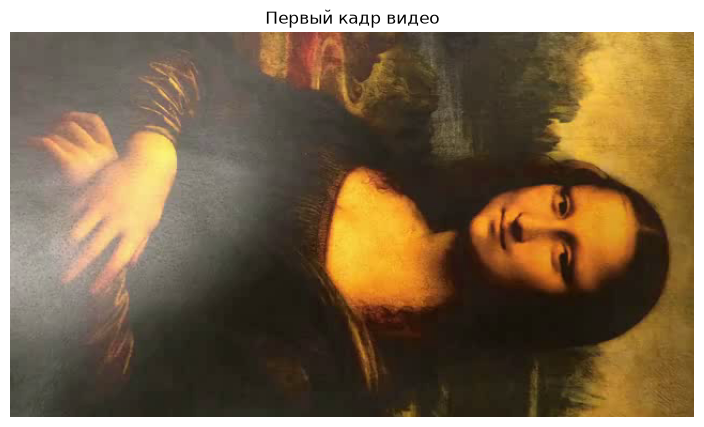

In [131]:
# Считываем первый кадр видео
success, first_frame = cap.read()

# Проверяем, удалось ли получить кадр
if not success:
    raise ValueError("Не удалось получить первый кадр!")

# Переводим изображение из BGR в RGB
first_frame_rgb = cv2.cvtColor(
    first_frame,
    cv2.COLOR_BGR2RGB
)

# Отображаем первый кадр
plt.figure(figsize=(10, 5))
plt.imshow(first_frame_rgb)
plt.title("Первый кадр видео")
plt.axis("off")
plt.show()

# Закрываем видео
cap.release()

Поиск ключевых точек ORB

Количество ключевых точек: 1660


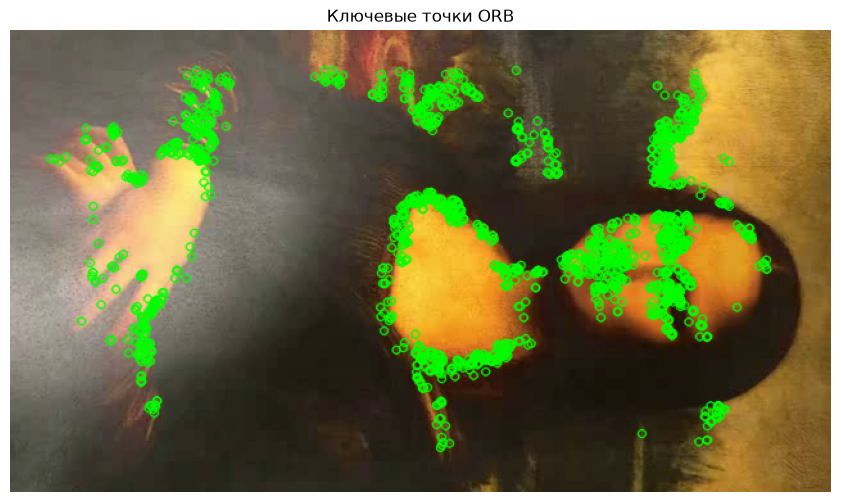

In [132]:
# Переводим первый кадр в оттенки серого
gray_frame = cv2.cvtColor(
    first_frame,
    cv2.COLOR_BGR2GRAY
)

# Создаём ORB с улучшенными параметрами
orb = cv2.ORB_create(
    nfeatures=2000,      # Максимальное количество ключевых точек
    scaleFactor=1.2,     # Коэффициент изменения масштаба
    nlevels=12,          # Количество уровней масштабирования
    fastThreshold=10     # Чувствительность поиска ключевых точек
)

# Находим ключевые точки и их дескрипторы
keypoints, descriptors = orb.detectAndCompute(
    gray_frame,
    None
)

# Рисуем ключевые точки на изображении
keypoints_image = cv2.drawKeypoints(
    first_frame,
    keypoints,
    None,
    color=(0, 255, 0)
)

print("Количество ключевых точек:", len(keypoints))

# Отображаем результат
plt.figure(figsize=(12, 6))
plt.imshow(
    cv2.cvtColor(keypoints_image, cv2.COLOR_BGR2RGB)
)
plt.title("Ключевые точки ORB")
plt.axis("off")
plt.show()


Получение следующего кадра

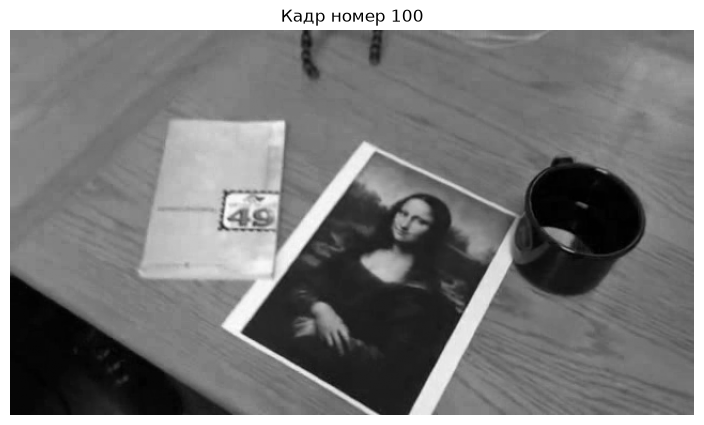

In [133]:
# Открываем выбранное для демонстрации видео повторно
cap = cv2.VideoCapture(str(VIDEO_PATH))

# Выбираем кадр номер 100.
# Если видео короче, используем его последний кадр.
frame_number = min(100, max(0, frame_count - 1))

# Переходим к нужному кадру
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)

# Считываем кадр
success, current_frame = cap.read()

# Проверяем, удалось ли получить кадр
if not success:
    cap.release()
    raise ValueError("Не удалось получить кадр для демонстрации!")

# Переводим кадр в оттенки серого
current_gray = cv2.cvtColor(
    current_frame,
    cv2.COLOR_BGR2GRAY
)

# Отображаем кадр
plt.figure(figsize=(10, 5))
plt.imshow(current_gray, cmap="gray")
plt.title(f"Кадр номер {frame_number}")
plt.axis("off")
plt.show()

# Закрываем видео
cap.release()


Поиск ключевых точек на новом кадре

In [134]:
# Находим ключевые точки и дескрипторы нового кадра
current_keypoints, current_descriptors = orb.detectAndCompute(
    current_gray,
    None
)

# Проверяем количество найденных точек
print("Ключевых точек первого кадра:", len(keypoints))
print("Ключевых точек текущего кадра:", len(current_keypoints))

Ключевых точек первого кадра: 1660
Ключевых точек текущего кадра: 1808


Сопоставление дескрипторов

In [135]:
# Создаём объект для сопоставления дескрипторов
# NORM_HAMMING подходит для бинарных дескрипторов ORB
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

# Ищем два наиболее похожих совпадения для каждой точки
matches = matcher.knnMatch(
    descriptors,
    current_descriptors,
    k=2
)

# Создаём список для хороших совпадений
good_matches = []

# Применяем Ratio Test
for pair in matches:

    # Проверяем, что найдено два совпадения
    if len(pair) == 2:

        # Получаем два наиболее похожих совпадения
        first_match, second_match = pair

        # Оставляем совпадение, если оно достаточно надёжное
        if first_match.distance < 0.75 * second_match.distance:
            good_matches.append(first_match)

# Сортируем совпадения по качеству
good_matches = sorted(
    good_matches,
    key=lambda match: match.distance
)

print("Количество хороших совпадений:", len(good_matches))

Количество хороших совпадений: 62


Визуализация совпадений

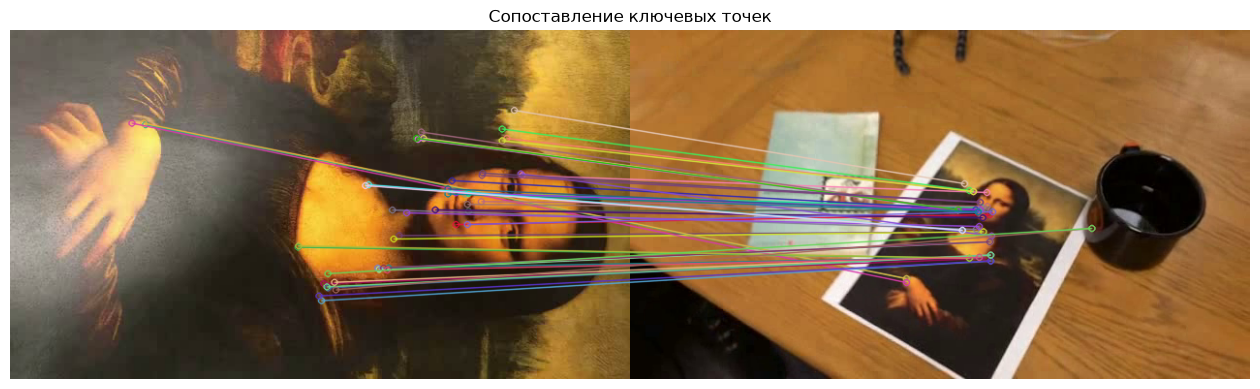

In [136]:
# Выбираем 50 лучших совпадений
display_matches = good_matches[:50]

# Рисуем линии между совпадающими точками
matches_image = cv2.drawMatches(
    first_frame,
    keypoints,
    current_frame,
    current_keypoints,
    display_matches,
    None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Преобразуем изображение из BGR в RGB
matches_image = cv2.cvtColor(
    matches_image,
    cv2.COLOR_BGR2RGB
)

# Отображаем результат
plt.figure(figsize=(16, 7))
plt.imshow(matches_image)
plt.title("Сопоставление ключевых точек")
plt.axis("off")
plt.show()

# Сохраняем изображение
plt.imsave(
    RESULTS_DIR / "feature_matching.png",
    matches_image
)

Вычисление матрицы гомографии

In [137]:
# Проверяем, достаточно ли совпадений
if len(good_matches) < 4:
    raise ValueError("Недостаточно совпадений для вычисления гомографии!")


# Получаем координаты совпадающих точек первого изображения
src_pts = np.float32([
    keypoints[m.queryIdx].pt
    for m in good_matches
]).reshape(-1, 1, 2)


# Получаем координаты соответствующих точек текущего изображения
dst_pts = np.float32([
    current_keypoints[m.trainIdx].pt
    for m in good_matches
]).reshape(-1, 1, 2)


# Вычисляем матрицу гомографии с помощью RANSAC
homography, mask = cv2.findHomography(
    src_pts,
    dst_pts,
    cv2.RANSAC,
    5.0
)


# Проверяем, удалось ли вычислить матрицу
if homography is None:
    raise ValueError("Не удалось вычислить матрицу гомографии!")


# Получаем маску правильных совпадений
matches_mask = mask.ravel().tolist()

# Считаем количество правильных совпадений
inliers = sum(matches_mask)

print("Всего хороших совпадений:", len(good_matches))
print("Правильных совпадений после RANSAC:", inliers)
print("Ошибочных совпадений:", len(good_matches) - inliers)

Всего хороших совпадений: 62
Правильных совпадений после RANSAC: 52
Ошибочных совпадений: 10


Отображение правильных совпадений

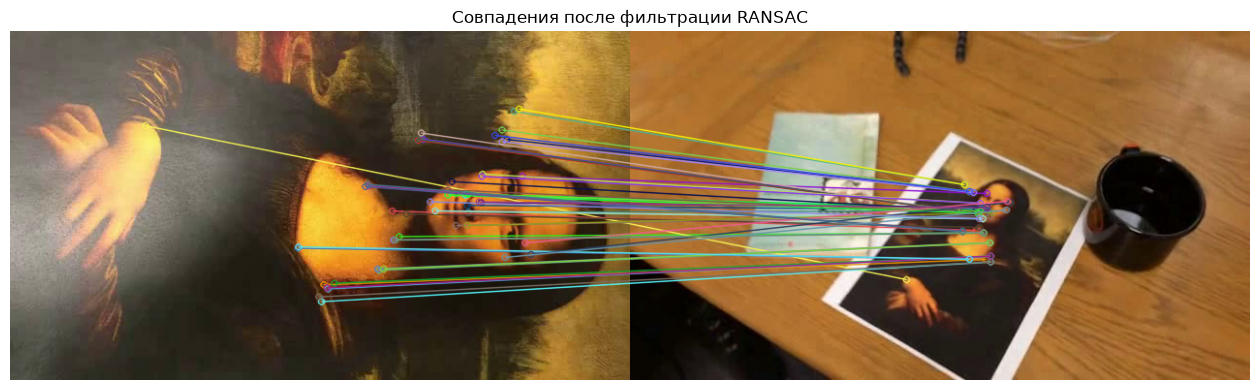

In [138]:
# Рисуем только правильные совпадения
inlier_matches_image = cv2.drawMatches(
    first_frame,
    keypoints,
    current_frame,
    current_keypoints,
    good_matches,
    None,
    matchesMask=matches_mask,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

# Переводим изображение из BGR в RGB
inlier_matches_image = cv2.cvtColor(
    inlier_matches_image,
    cv2.COLOR_BGR2RGB
)

# Отображаем результат
plt.figure(figsize=(16, 7))

plt.imshow(inlier_matches_image)
plt.title("Совпадения после фильтрации RANSAC")
plt.axis("off")

plt.show()

# Сохраняем результат
plt.imsave(
    RESULTS_DIR / "ransac_matches.png",
    inlier_matches_image
)

Рисуем рамку вокруг объекта

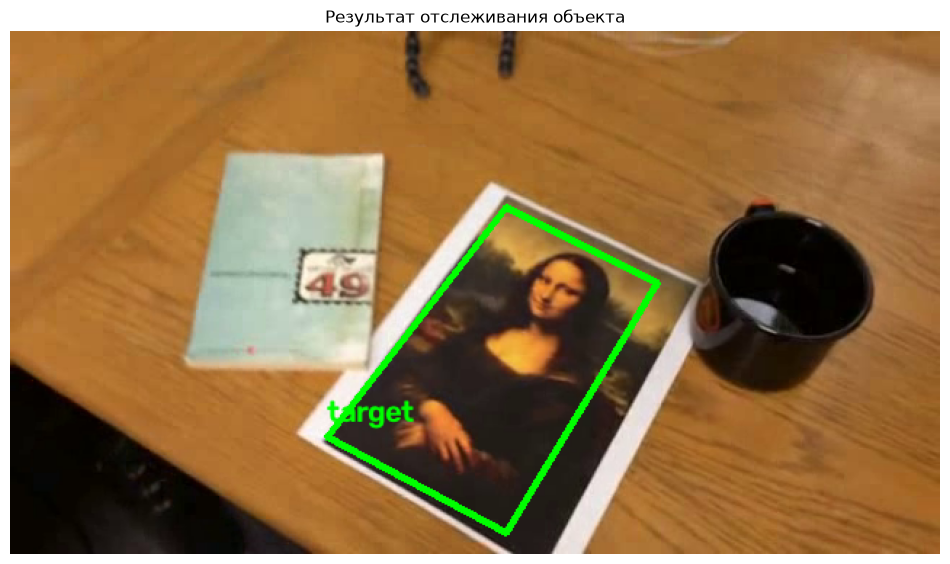

In [139]:
# Получаем размеры первого кадра
height, width = first_frame.shape[:2]


# Создаём координаты четырёх углов исходного изображения
corners = np.float32([
    [0, 0],
    [width - 1, 0],
    [width - 1, height - 1],
    [0, height - 1]
]).reshape(-1, 1, 2)


# Переносим углы в координаты текущего кадра
transformed_corners = cv2.perspectiveTransform(
    corners,
    homography
)


# Создаём копию текущего кадра
result_frame = current_frame.copy()


# Рисуем рамку вокруг найденного объекта
cv2.polylines(
    result_frame,
    [np.int32(transformed_corners)],
    True,
    (0, 255, 0),
    3
)


# Добавляем подпись
x = max(0, int(transformed_corners[0][0][0]))
y = max(25, int(transformed_corners[0][0][1]) - 10)

cv2.putText(
    result_frame,
    "target",
    (x, y),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.7,
    (0, 255, 0),
    2
)


# Переводим изображение из BGR в RGB
result_rgb = cv2.cvtColor(
    result_frame,
    cv2.COLOR_BGR2RGB
)


# Отображаем результат
plt.figure(figsize=(12, 7))
plt.imshow(result_rgb)
plt.title("Результат отслеживания объекта")
plt.axis("off")
plt.show()


# Сохраняем изображение
plt.imsave(
    RESULTS_DIR / "tracking_result.png",
    result_rgb
)

Вспомогательные функции алгоритма


In [140]:
# Функция для вычисления и проверки гомографии
def estimate_homography(
    ref_pts,
    cur_pts,
    reference_corners,
    width,
    height,
    min_inliers=8,
    min_ratio=0.35,
    ransac_threshold=4.0,
    min_coverage=0.06
):
    # Проверяем количество точек
    if ref_pts is None or cur_pts is None or len(ref_pts) < 4:
        return None

    # Вычисляем матрицу гомографии
    H, mask = cv2.findHomography(
        ref_pts,
        cur_pts,
        cv2.RANSAC,
        ransac_threshold
    )

    if H is None or mask is None:
        return None

    # Получаем правильные совпадения
    inliers_mask = mask.ravel().astype(bool)
    inliers_count = int(np.sum(inliers_mask))
    inlier_ratio = inliers_count / len(ref_pts)

    # Проверяем надёжность совпадений
    if inliers_count < min_inliers or inlier_ratio < min_ratio:
        return None

    # Проверяем, что правильные точки распределены по объекту
    inlier_ref_points = ref_pts[inliers_mask].reshape(-1, 2)

    hull = cv2.convexHull(
        inlier_ref_points.astype(np.float32)
    )

    coverage = cv2.contourArea(hull) / (width * height)

    if coverage < min_coverage:
        return None

    # Переносим углы исходного изображения в текущий кадр
    transformed = cv2.perspectiveTransform(
        reference_corners,
        H
    )

    points = transformed.reshape(-1, 2)

    if not np.isfinite(points).all():
        return None

    polygon = np.int32(points)

    # Проверяем площадь рамки
    area = abs(cv2.contourArea(polygon)) / (width * height)

    # Проверяем длину сторон
    edge_lengths = np.linalg.norm(
        np.roll(points, -1, axis=0) - points,
        axis=1
    )

    # Разрешаем небольшой выход рамки за границы кадра
    inside_limits = (
        np.all(points[:, 0] >= -0.15 * width)
        and np.all(points[:, 0] <= 1.15 * width)
        and np.all(points[:, 1] >= -0.15 * height)
        and np.all(points[:, 1] <= 1.15 * height)
    )

    # Проверяем корректность полученной рамки
    valid_geometry = (
        inside_limits
        and 0.002 < area < 0.9
        and np.min(edge_lengths) > 8
        and cv2.isContourConvex(polygon)
    )

    if not valid_geometry:
        return None

    # Возвращаем матрицу, маску правильных точек и координаты рамки
    return {
        "homography": H,
        "inliers_mask": inliers_mask,
        "polygon": polygon,
        "points": points,
        "coverage": coverage
    }


# Функция для добавления новых ключевых точек внутри рамки объекта
def add_new_points(
    gray,
    polygon,
    H,
    current_points,
    ref_points,
    orb,
    width,
    height
):
    # Создаём маску области объекта
    roi_mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    cv2.fillConvexPoly(
        roi_mask,
        polygon,
        255
    )

    # Ищем новые ключевые точки только внутри рамки
    new_keypoints = orb.detect(
        gray,
        roi_mask
    )

    if not new_keypoints:
        return current_points, ref_points

    existing_points = current_points.reshape(-1, 2)
    added_points = []

    # Ограничиваем общее количество отслеживаемых точек
    max_total_points = 1500
    max_new_points = min(
        150,
        max_total_points - len(existing_points)
    )

    if max_new_points <= 0:
        return current_points, ref_points

    # Добавляем точки, которые находятся не слишком близко к старым
    for kp in new_keypoints:
        point = np.float32(kp.pt)

        if (
            len(existing_points) == 0
            or np.min(
                np.linalg.norm(existing_points - point, axis=1)
            ) > 8
        ):
            added_points.append(point)

            existing_points = np.vstack([
                existing_points,
                point
            ])

        if len(added_points) >= max_new_points:
            break

    if not added_points:
        return current_points, ref_points

    # Преобразуем новые точки в нужный формат
    new_current_points = np.float32(
        added_points
    ).reshape(-1, 1, 2)

    # Переводим новые точки из текущего кадра в координаты первого кадра
    try:
        inverse_H = np.linalg.inv(H)
    except np.linalg.LinAlgError:
        return current_points, ref_points

    new_reference_points = cv2.perspectiveTransform(
        new_current_points,
        inverse_H
    )

    # Добавляем новые точки к уже существующим
    current_points = np.concatenate([
        current_points,
        new_current_points
    ], axis=0)

    ref_points = np.concatenate([
        ref_points,
        new_reference_points
    ], axis=0)

    return current_points, ref_points


Основная функция обработки одного видео


In [141]:
# Функция обрабатывает одно видео и сохраняет результат в папку results
def track_video(video_path):
    print("\n" + "=" * 60)
    print("Обработка видео:", video_path.name)
    print("=" * 60)

    # Открываем исходное видео
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        print("Не удалось открыть видео:", video_path.name)
        cap.release()
        return None

    writer = None

    try:
        # Получаем характеристики видео
        fps = cap.get(cv2.CAP_PROP_FPS)
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        # Если FPS не удалось определить, используем 25
        if fps <= 0:
            fps = 25.0

        # Считываем первый кадр — образец объекта
        success, first_frame = cap.read()

        if not success:
            print("Не удалось получить первый кадр:", video_path.name)
            return None

        # Переводим первый кадр в оттенки серого
        reference_gray = cv2.cvtColor(
            first_frame,
            cv2.COLOR_BGR2GRAY
        )

        # Создаём ORB для поиска ключевых точек
        orb = cv2.ORB_create(
            nfeatures=2000,
            scaleFactor=1.2,
            nlevels=12,
            fastThreshold=10
        )

        # Находим ключевые точки и дескрипторы первого кадра
        reference_keypoints, reference_descriptors = orb.detectAndCompute(
            reference_gray,
            None
        )

        if (
            reference_descriptors is None
            or len(reference_keypoints) < 8
        ):
            print("Недостаточно ключевых точек:", video_path.name)
            return None

        # Получаем координаты ключевых точек
        reference_points = np.float32([
            kp.pt for kp in reference_keypoints
        ]).reshape(-1, 1, 2)

        # Создаём координаты четырёх углов первого кадра
        reference_corners = np.float32([
            [0, 0],
            [width - 1, 0],
            [width - 1, height - 1],
            [0, height - 1]
        ]).reshape(-1, 1, 2)

        # Начальные точки для Lucas-Kanade
        previous_gray = reference_gray.copy()
        previous_points = reference_points.copy()
        previous_reference_points = reference_points.copy()

        # Создаём объект для сопоставления дескрипторов
        matcher = cv2.BFMatcher(cv2.NORM_HAMMING)

        # Формируем имя выходного файла автоматически
        output_path = RESULTS_DIR / f"{video_path.stem}_tracking.avi"

        # Создаём объект для записи видео
        fourcc = cv2.VideoWriter_fourcc(*"MJPG")

        writer = cv2.VideoWriter(
            str(output_path),
            fourcc,
            fps,
            (width, height)
        )

        if not writer.isOpened():
            print("Не удалось создать выходное видео:", output_path.name)
            return None

        # Сохраняем первый кадр без изменений
        writer.write(first_frame)

        # Счётчики результатов
        frame_number = 1
        tracked_frames = 0
        detected_frames = 0
        lk_detections = 0
        orb_reacquisitions = 0
        not_found_frames = 0

        # Перебираем все оставшиеся кадры видео
        while True:
            success, frame = cap.read()

            if not success:
                break

            frame_number += 1
            tracked_frames += 1

            # Переводим кадр в оттенки серого
            gray = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2GRAY
            )

            result = frame.copy()
            tracking_result = None
            method = None

            # Пустые массивы для точек текущего кадра
            lk_reference_points = np.empty(
                (0, 1, 2),
                dtype=np.float32
            )

            lk_current_points = np.empty(
                (0, 1, 2),
                dtype=np.float32
            )

            # =====================================
            # 1. Отслеживание точек Lucas-Kanade
            # =====================================

            if len(previous_points) >= 8:
                # Отслеживаем точки с предыдущего кадра на текущий
                next_points, status_forward, error_forward = cv2.calcOpticalFlowPyrLK(
                    previous_gray,
                    gray,
                    previous_points,
                    None,
                    winSize=(21, 21),
                    maxLevel=3,
                    criteria=(
                        cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
                        30,
                        0.01
                    )
                )

                if (
                    next_points is not None
                    and status_forward is not None
                    and error_forward is not None
                ):
                    # Проверяем перемещение в обратном направлении
                    backward_points, status_backward, _ = cv2.calcOpticalFlowPyrLK(
                        gray,
                        previous_gray,
                        next_points,
                        None,
                        winSize=(21, 21),
                        maxLevel=3,
                        criteria=(
                            cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT,
                            30,
                            0.01
                        )
                    )

                    if (
                        backward_points is not None
                        and status_backward is not None
                    ):
                        # Проверяем, насколько точно точки вернулись назад
                        forward_backward_error = np.linalg.norm(
                            previous_points.reshape(-1, 2)
                            - backward_points.reshape(-1, 2),
                            axis=1
                        )

                        # Оставляем только надёжно отслеженные точки
                        good_mask = (
                            status_forward.ravel().astype(bool)
                            & status_backward.ravel().astype(bool)
                            & np.isfinite(
                                next_points.reshape(-1, 2)
                            ).all(axis=1)
                            & (error_forward.ravel() < 40)
                            & (forward_backward_error < 1.5)
                        )

                        lk_reference_points = previous_reference_points[good_mask]

                        lk_current_points = next_points[good_mask].reshape(
                            -1, 1, 2
                        )

                        # Проверяем перемещение точек через RANSAC
                        tracking_result = estimate_homography(
                            lk_reference_points,
                            lk_current_points,
                            reference_corners,
                            width,
                            height
                        )

                        if tracking_result is not None:
                            method = "Lucas-Kanade"

            # =====================================
            # 2. Повторный поиск объекта через ORB
            # =====================================

            # Запускаем ORB каждые 10 кадров или при потере объекта
            need_orb_search = (
                frame_number % 10 == 0
                or tracking_result is None
            )

            if need_orb_search:
                current_keypoints, current_descriptors = orb.detectAndCompute(
                    gray,
                    None
                )

                if (
                    current_descriptors is not None
                    and len(current_descriptors) >= 2
                ):
                    # Сопоставляем дескрипторы первого и текущего кадров
                    pairs = matcher.knnMatch(
                        reference_descriptors,
                        current_descriptors,
                        k=2
                    )

                    # Оставляем хорошие совпадения по Ratio Test
                    good_matches = [
                        pair[0]
                        for pair in pairs
                        if (
                            len(pair) == 2
                            and pair[0].distance < 0.75 * pair[1].distance
                        )
                    ]

                    if len(good_matches) >= 10:
                        # Координаты точек первого кадра
                        orb_reference_points = np.float32([
                            reference_keypoints[m.queryIdx].pt
                            for m in good_matches
                        ]).reshape(-1, 1, 2)

                        # Координаты соответствующих точек текущего кадра
                        orb_current_points = np.float32([
                            current_keypoints[m.trainIdx].pt
                            for m in good_matches
                        ]).reshape(-1, 1, 2)

                        # Проверяем совпадения через RANSAC
                        orb_result = estimate_homography(
                            orb_reference_points,
                            orb_current_points,
                            reference_corners,
                            width,
                            height,
                            min_inliers=10,
                            min_ratio=0.45,
                            ransac_threshold=5.0,
                            min_coverage=0.04
                        )

                        if orb_result is not None:
                            tracking_result = orb_result
                            method = "ORB"
                            orb_reacquisitions += 1

                            # Оставляем только правильные совпадения
                            inliers_mask = orb_result["inliers_mask"]

                            next_reference_points = orb_reference_points[
                                inliers_mask
                            ].copy()

                            next_points = orb_current_points[
                                inliers_mask
                            ].copy()

            # =====================================
            # 3. Обновление положения объекта
            # =====================================

            if tracking_result is not None:
                detected_frames += 1

                # Если использовался Lucas-Kanade,
                # оставляем только правильные точки RANSAC
                if method == "Lucas-Kanade":
                    inliers_mask = tracking_result["inliers_mask"]

                    next_reference_points = lk_reference_points[
                        inliers_mask
                    ].copy()

                    next_points = lk_current_points[
                        inliers_mask
                    ].copy()

                    lk_detections += 1

                # Получаем координаты рамки
                polygon = tracking_result["polygon"]
                points = tracking_result["points"]

                # Рисуем рамку вокруг найденного объекта
                cv2.polylines(
                    result,
                    [polygon],
                    True,
                    (0, 255, 0),
                    2
                )

                # Координаты подписи
                x = max(0, min(width - 1, int(points[0][0])))
                y = max(25, min(height - 1, int(points[0][1]) - 10))

                # Подписываем объект универсальным названием
                cv2.putText(
                    result,
                    "target",
                    (x, y),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (0, 255, 0),
                    2
                )

                # Периодически добавляем новые ключевые точки
                if frame_number % 5 == 0 or len(next_points) < 250:
                    next_points, next_reference_points = add_new_points(
                        gray,
                        polygon,
                        tracking_result["homography"],
                        next_points,
                        next_reference_points,
                        orb,
                        width,
                        height
                    )

                # Сохраняем точки для следующего кадра
                previous_points = next_points.copy()
                previous_reference_points = next_reference_points.copy()

            else:
                # Если объект не найден
                not_found_frames += 1

                # Сохраняем точки, которые удалось отследить
                previous_points = lk_current_points.copy()
                previous_reference_points = lk_reference_points.copy()

                # Показываем предупреждение
                cv2.putText(
                    result,
                    "Object not found",
                    (20, 30),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.65,
                    (0, 0, 255),
                    2
                )

            # Обновляем предыдущий кадр
            previous_gray = gray.copy()

            # Записываем обработанный кадр
            writer.write(result)

            # Выводим прогресс
            if frame_number % 50 == 0:
                print(f"{video_path.name}: обработано кадров {frame_number}")

        # Рассчитываем процент обнаружения
        percentage = (
            detected_frames / tracked_frames * 100
            if tracked_frames > 0 else 0
        )

        # Выводим статистику по текущему видео
        print("\nОбработка завершена!")
        print("Всего кадров:", frame_number)
        print("Успешно найден объект:", detected_frames)
        print("Обнаружения Lucas-Kanade:", lk_detections)
        print("Повторные обнаружения ORB:", orb_reacquisitions)
        print("Пропущено кадров:", not_found_frames)
        print(f"Процент обнаружения: {percentage:.2f}%")
        print("Результат сохранён:", output_path)

        # Возвращаем статистику для общей таблицы
        return {
            "video": video_path.name,
            "output": output_path.name,
            "output_path": output_path,
            "total_frames": frame_number,
            "tracked_frames": tracked_frames,
            "detected_frames": detected_frames,
            "percentage": percentage,
            "lk_detections": lk_detections,
            "orb_reacquisitions": orb_reacquisitions,
            "not_found_frames": not_found_frames
        }

    finally:
        # Закрываем видео и освобождаем файл записи
        cap.release()

        if writer is not None:
            writer.release()


Автоматическая обработка всех видео


In [142]:
# Список для хранения результатов обработки
all_results = []

# Обрабатываем каждое видео из папки videos
for video_path in video_files:
    stats = track_video(video_path)

    if stats is not None:
        all_results.append(stats)


# Выводим общую таблицу результатов
print("\n" + "=" * 85)
print("ИТОГИ ОБРАБОТКИ ВСЕХ ВИДЕО")
print("=" * 85)

if all_results:
    print(
        f"{'Видео':<32} {'Кадров':>10} {'Найдено':>10} "
        f"{'Обнаружение':>14} {'Пропущено':>12}"
    )
    print("-" * 85)

    for item in all_results:
        print(
            f"{item['video']:<32} "
            f"{item['total_frames']:>10} "
            f"{item['detected_frames']:>10} "
            f"{item['percentage']:>13.2f}% "
            f"{item['not_found_frames']:>12}"
        )

    print("\nУспешно обработано видео:", len(all_results))
else:
    print("Ни одно видео не удалось обработать.")



Обработка видео: mona-lisa-blur-extra-credit.avi
mona-lisa-blur-extra-credit.avi: обработано кадров 50
mona-lisa-blur-extra-credit.avi: обработано кадров 100
mona-lisa-blur-extra-credit.avi: обработано кадров 150
mona-lisa-blur-extra-credit.avi: обработано кадров 200
mona-lisa-blur-extra-credit.avi: обработано кадров 250
mona-lisa-blur-extra-credit.avi: обработано кадров 300
mona-lisa-blur-extra-credit.avi: обработано кадров 350
mona-lisa-blur-extra-credit.avi: обработано кадров 400
mona-lisa-blur-extra-credit.avi: обработано кадров 450
mona-lisa-blur-extra-credit.avi: обработано кадров 500
mona-lisa-blur-extra-credit.avi: обработано кадров 550

Обработка завершена!
Всего кадров: 558
Успешно найден объект: 522
Обнаружения Lucas-Kanade: 500
Повторные обнаружения ORB: 22
Пропущено кадров: 35
Процент обнаружения: 93.72%
Результат сохранён: results\mona-lisa-blur-extra-credit_tracking.avi

Обработка видео: mona-lisa-blur.avi
mona-lisa-blur.avi: обработано кадров 50
mona-lisa-blur.avi: обр

Просмотр результата


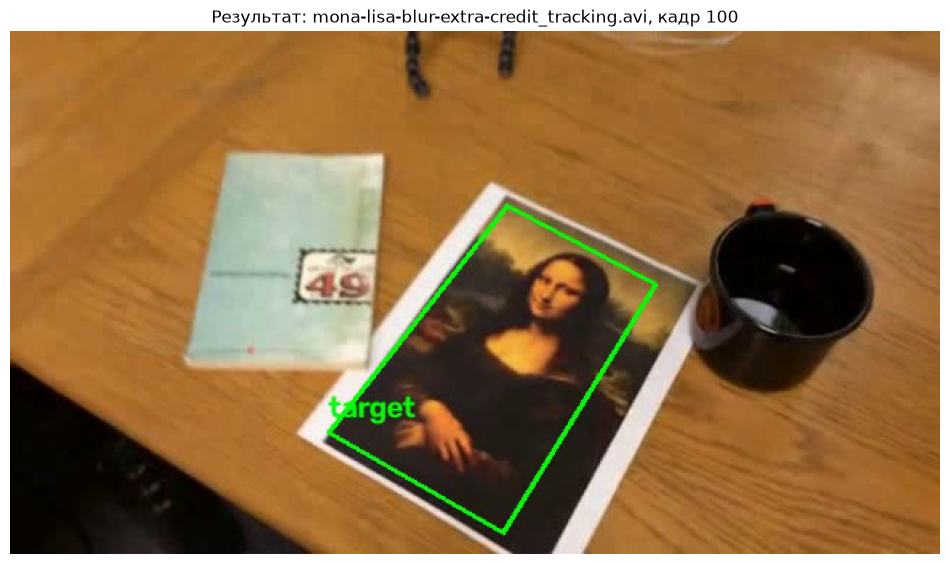

Превью сохранено: results\mona-lisa-blur-extra-credit_tracking_preview.png


In [143]:
# Показываем результат обработки первого видео из списка
if not all_results:
    print("Нет обработанных видео для просмотра.")

else:
    # Берём путь к первому обработанному видео
    preview_path = all_results[0]["output_path"]

    # Открываем обработанное видео
    result_video = cv2.VideoCapture(str(preview_path))

    # Получаем количество кадров
    preview_frame_count = int(
        result_video.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    # Выбираем кадр номер 100 или последний доступный
    preview_frame_number = min(
        100,
        max(0, preview_frame_count - 1)
    )

    result_video.set(
        cv2.CAP_PROP_POS_FRAMES,
        preview_frame_number
    )

    # Считываем кадр
    success, preview = result_video.read()

    if success:
        # Переводим изображение из BGR в RGB
        preview_rgb = cv2.cvtColor(
            preview,
            cv2.COLOR_BGR2RGB
        )

        # Отображаем результат
        plt.figure(figsize=(12, 7))
        plt.imshow(preview_rgb)
        plt.title(
            f"Результат: {preview_path.name}, "
            f"кадр {preview_frame_number}"
        )
        plt.axis("off")
        plt.show()

        # Сохраняем изображение
        preview_image_path = (
            RESULTS_DIR / f"{preview_path.stem}_preview.png"
        )

        plt.imsave(
            preview_image_path,
            preview_rgb
        )

        print("Превью сохранено:", preview_image_path)

    else:
        print("Не удалось прочитать кадр обработанного видео.")

    # Закрываем видео
    result_video.release()
